## وارد کردن کتابخانه های مورد نیاز: 


In [1]:
from pathlib import Path
import re
import ast
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import ParameterGrid
from scipy import sparse
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

print("done!!")

done!!


## بارگذاری دیتاهای اماده شده در انتهای فاز یک: 

In [2]:
DATA_DIR = Path("data/extracted")
REVIEWS_PATH = DATA_DIR / "reviews_clean.pkl"
METADATA_PATH = DATA_DIR / "metadata_clean.pkl"

if not REVIEWS_PATH.exists():
    raise FileNotFoundError(f" {REVIEWS_PATH.resolve()}")
if not METADATA_PATH.exists():
    raise FileNotFoundError(f" {METADATA_PATH.resolve()}")

reviews_clean = pd.read_pickle(REVIEWS_PATH)
metadata_clean = pd.read_pickle(METADATA_PATH)

print("Reviews:", reviews_clean.shape)
print("Metadata:", metadata_clean.shape)
display(reviews_clean.head(3))
display(metadata_clean.head(3))


Reviews: (99859, 10)
Metadata: (55902, 13)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,Good but...,I like the concept of this a lot and it works ...,[],B001FUBS5K,B001FUBS5K,AHX46DHDWT3EWIGZL73EVWAIHKPQ,1401214324000,0,True
1,2.0,Wouldn't buy again,Peels off within days,[],B00PF9Q5EG,B00PF9Q5EG,AFVVPTSROUQQHFTOVXQ4LNDIQ2YQ,1491877013000,0,True
2,3.0,Didn’t really work that good.,Had higher hopes for this product. Didn’t real...,[],B009GA5XVG,B009GA5XVG,AHJ7TZF6TKQS26FOO5AN7KGCNXHQ,1522702812287,1,True


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin
0,All Beauty,"L.A. COLORS 5 Color Matte Eyeshadow, Brown Twe...",4.3,5367,"[Intense color, Matte finish, Silky texture]","[Wrap yourself in soft, cozy color. These matt...",2.49,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'LA Colors Pallete Review - YOU MUS...,L.A. COLORS,"[Beauty & Personal Care, Makeup, Eyes, Eyeshadow]","{'Color': 'Brown Tweed', 'Brand': 'L.A. COLORS...",B01DX1OEFO
1,All Beauty,Paloma Picasso for Women By Paloma Picasso 6.7...,4.2,85,"[100% Genuine Guaranteed, Safety & Security Gu...",[BODY LOTION 6.7 OZ for female],None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Paloma Picasso Full Fragrance Revi...,Paloma Picasso,"[Beauty & Personal Care, Skin Care, Body, Mois...","{'Brand': 'Paloma Picasso', 'Scent': 'Citrus',...",B000M86E3C
2,All Beauty,Newcally Natural Look Lashes Mink 3D Fluffy Wi...,4.4,34981,[The natural false eyelashes are fluffy and so...,[],9.45,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'My favorite lashes ', 'url': 'http...",Newcally,"[Beauty & Personal Care, Tools & Accessories, ...","{'Color': 'Black', 'Brand': 'Newcally', 'Mater...",B09WHMND5W


## از اونجایی که 100000 دیتا برای پردازش خیلی زیاد بود من یک زیر مجموعهی تصادفی 10000 تایی دریافت میکنم

In [3]:
# تعداد نمونه موردنظر
SAMPLE_SIZE = 1000

# بررسی ابعاد دیتاست
print("Original dataset shape:", reviews_clean.shape)

# انتخاب نمونه تصادفی
reviews_sample = reviews_clean.sample(
    n=min(SAMPLE_SIZE, len(reviews_clean)),
    random_state=42
).copy()

# ذخیره نمونه
reviews_sample.to_pickle("reviews_sample_10000.pkl")

# بررسی نتیجه
print("Sample dataset shape:", reviews_sample.shape)
print("Sample saved successfully!")

Original dataset shape: (99859, 10)
Sample dataset shape: (1000, 10)
Sample saved successfully!


In [3]:
REVIEWS_PATH ="reviews_sample_10000.pkl"
reviews_sample = pd.read_pickle(REVIEWS_PATH)

## ادغام دو دیتاست:

In [4]:
required_reviews = ["parent_asin", "text", "rating", "timestamp", "helpful_vote"]
missing_reviews = [c for c in required_reviews if c not in reviews_sample.columns]
if missing_reviews:
    raise KeyError(f"  {missing_reviews}")
if "parent_asin" not in metadata_clean.columns:
    raise KeyError("error.")

print("duplicted: ",
      metadata_clean["parent_asin"].duplicated(keep=False).sum())

metadata_for_merge = metadata_clean.drop_duplicates(
    subset=["parent_asin"], keep="first"
).copy()

data = reviews_sample.merge(
    metadata_for_merge,
    on="parent_asin",
    how="left",
    suffixes=("_review", "_meta"),
    validate="many_to_one"
)

assert len(data) == len(reviews_sample), "difference : ."
print("Merged data:", data.shape)
display(data.head(3))


duplicted:  0
Merged data: (1000, 22)


,rating,title_review,text,images_review,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,main_category,title_meta,average_rating,rating_number,features,description,price,images_meta,videos,store,categories,details
0,5.0,!!,This product seriously did wonders to my skin,[],B0043OYFKU,B0043OYFKU,AEQYQRBFKKSYWR5QHVEUD6JL6A4Q,1440356318000,0,True,All Beauty,Olay Pro-X Advanced Cleansing System + 20 ml R...,4.2,7175,[2-speed rotating facial cleansing brush deliv...,"[Product Description, Take your facial cleansi...",None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'haven't tried the clairisonic but ...,Olay,"[Beauty & Personal Care, Skin Care, Face, Sets...","{'Brand': 'Olay', 'Age Range (Description)': '..."
1,5.0,Wonderful mint scent,"Smells so good! The container broke in route, ...",[],B07R5VCPDM,B08WKXP9NN,AGG4LMBGNUAD4LRH27LFN3SRRAYA,1580761959661,0,True,Health & Personal Care,Sapadilla Liquid Hand Soap - Rosemary + Pepper...,4.4,7100,[Smells HANDS Down Amazing: Treat yourself eve...,[Sapadilla Liquid Pump Hand Soap smells HANDS ...,24.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Sapadilla Hand Soap - Leave Your H...,Sapadilla,"[Beauty & Personal Care, Skin Care, Body, Clea...","{'Manufacturer': 'Sapadilla Soap Company', 'Pa..."
2,5.0,Five Stars,came as stated.,[],B006QYZS7E,B006QYZS7E,AHGYVAMJW4OHDZ2MIFLURL4TWEGQ,1435536507000,0,True,All Beauty,"Irish Spring Deodorant Bar Soap, Moisture Blas...",4.2,21,[],[Irish Spring Moisture Blast Scent Deodorant S...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],Irish Spring,"[Beauty & Personal Care, Skin Care, Body, Clea...","{'Is Discontinued By Manufacturer': 'No', 'Pro..."


## Modalities: 

,ستون,وجه اطلاعاتی,وجود ستون,تعداد معتبر/موجود,تعداد ناموجود/نامعتبر,درصد معتبر/موجود
0,rating,امتیاز نقد,True,1000,0,100.0
1,title_review,متن نقد,True,1000,0,100.0
2,text,متن نقد,True,1000,0,100.0
3,images_review,تصویر نقد,True,66,934,6.6
4,asin,شناسه محصول,True,1000,0,100.0
5,parent_asin,شناسه محصول / اتصال جداول,True,1000,0,100.0
6,user_id,شناسه کاربر,True,1000,0,100.0
7,timestamp,زمان,True,1000,0,100.0
8,helpful_vote,هدف پروژه,True,1000,0,100.0
9,verified_purchase,تعامل / وضعیت خرید,True,1000,0,100.0


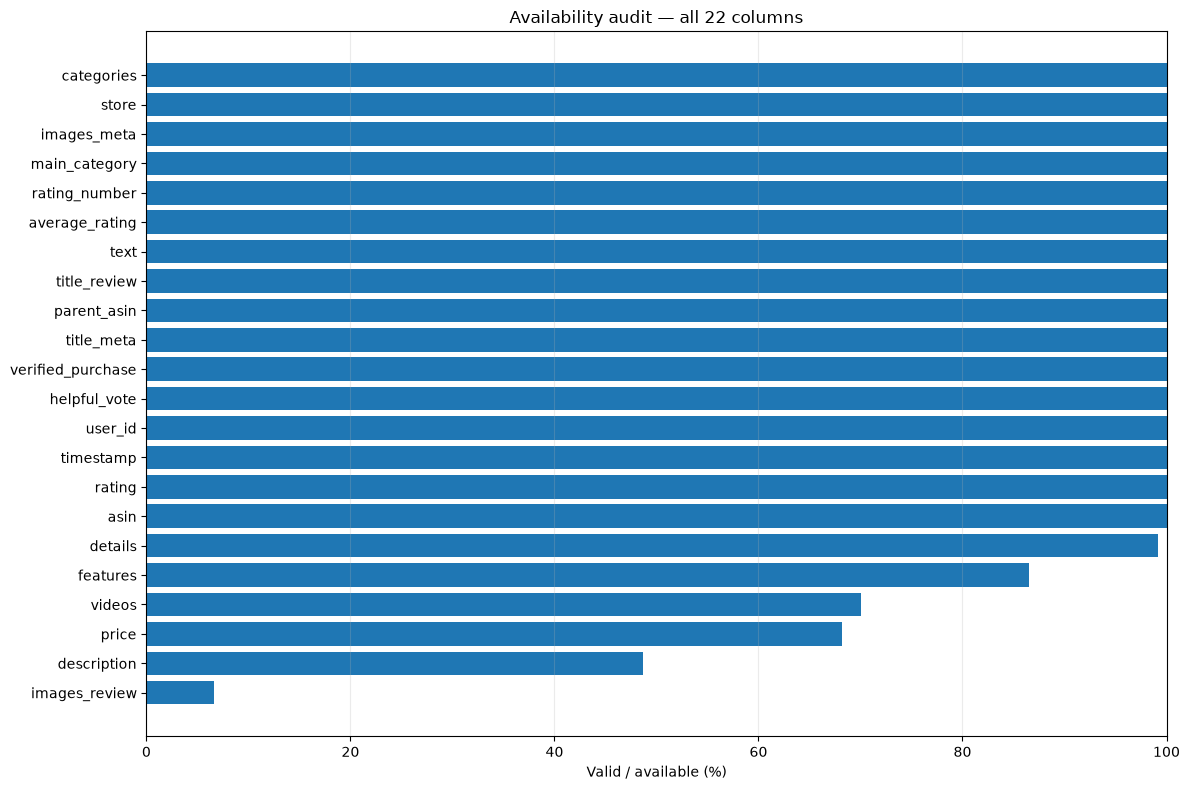

,میانگین درصد دسترسی
وجه اطلاعاتی,
امتیاز نقد,100.0
تصویر محصول,100.0
تعامل / وضعیت خرید,100.0
دسته‌بندی محصول,100.0
شناسه محصول,100.0
زمان,100.0
شناسه محصول / اتصال جداول,100.0
شناسه کاربر,100.0
هدف پروژه,100.0


In [28]:
def is_present(value):
    #بررسی موجود بودن اطلاعات سالم
    if value is None:
        return False
    if isinstance(value, str):
        return bool(value.strip())
    if isinstance(value, (list, tuple, set, dict, np.ndarray)):
        return len(value) > 0
    try:
        missing = pd.isna(value)
        if isinstance(missing, (bool, np.bool_)):
            return not missing
        return not bool(np.asarray(missing).all())
    except (TypeError, ValueError):
        return True

def as_numeric(series):
    return pd.to_numeric(series, errors="coerce")

def parse_price_series(series):
    cleaned = series.astype("string").str.replace(r"[$£€¥,]", "", regex=True).str.strip()
    return pd.to_numeric(cleaned, errors="coerce")

def parse_timestamp_series(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return pd.to_datetime(numeric, unit="ms", errors="coerce", utc=True)

def mask_present(column):
    return data[column].apply(is_present)

def mask_rating(column):
    x = as_numeric(data[column])
    return x.between(1, 5)

def mask_nonnegative(column):
    x = as_numeric(data[column])
    return x.notna() & (x >= 0)

def mask_helpful():
    x = as_numeric(data["helpful_vote"])
    return x.notna() & (x >= 0) & (x % 1 == 0)

def mask_price():
    x = parse_price_series(data["price"])
    return x.notna() & (x >= 0)

def mask_timestamp():
    return parse_timestamp_series(data["timestamp"]).notna()

def mask_boolean():
    valid_strings = data["verified_purchase"].apply(
        lambda x: isinstance(x, str) and x.strip().lower() in {"true", "false", "yes", "no", "0", "1"}
    )
    valid_native = data["verified_purchase"].apply(
        lambda x: isinstance(x, (bool, np.bool_))
    )
    valid_numeric = data["verified_purchase"].apply(
        lambda x: isinstance(x, (int, float, np.integer, np.floating))
        and not pd.isna(x) and x in (0, 1)
    )
    return valid_strings | valid_native | valid_numeric

column_checks = {
    "rating": lambda: mask_rating("rating"),
    "title_review": lambda: mask_present("title_review"),
    "text": lambda: mask_present("text"),
    "images_review": lambda: mask_present("images_review"),
    "asin": lambda: mask_present("asin"),
    "parent_asin": lambda: mask_present("parent_asin"),
    "user_id": lambda: mask_present("user_id"),
    "timestamp": mask_timestamp,
    "helpful_vote": lambda: mask_helpful(),
    "verified_purchase": mask_boolean,
    "main_category": lambda: mask_present("main_category"),
    "title_meta": lambda: mask_present("title_meta"),
    "average_rating": lambda: mask_rating("average_rating"),
    "rating_number": lambda: mask_nonnegative("rating_number"),
    "features": lambda: mask_present("features"),
    "description": lambda: mask_present("description"),
    "price": mask_price,
    "images_meta": lambda: mask_present("images_meta"),
    "videos": lambda: mask_present("videos"),
    "store": lambda: mask_present("store"),
    "categories": lambda: mask_present("categories"),
    "details": lambda: mask_present("details"),
}

modality_map = {
    "rating": "امتیاز نقد",
    "title_review": "متن نقد",
    "text": "متن نقد",
    "images_review": "تصویر نقد",
    "asin": "شناسه محصول",
    "parent_asin": "شناسه محصول / اتصال جداول",
    "user_id": "شناسه کاربر",
    "timestamp": "زمان",
    "helpful_vote": "هدف پروژه",
    "verified_purchase": "تعامل / وضعیت خرید",
    "main_category": "دسته‌بندی محصول",
    "title_meta": "فراداده محصول",
    "average_rating": "فراداده محصول",
    "rating_number": "فراداده محصول",
    "features": "متن/ویژگی محصول",
    "description": "متن/ویژگی محصول",
    "price": "قیمت محصول",
    "images_meta": "تصویر محصول",
    "videos": "ویدئوی محصول",
    "store": "فروشنده/برند",
    "categories": "دسته‌بندی محصول",
    "details": "فراداده محصول",
}

audit_rows = []
for col, check in column_checks.items():
    exists = col in data.columns
    if exists:
        valid_mask = check().reindex(data.index).fillna(False).astype(bool)
        valid_count = int(valid_mask.sum())
        invalid_count = int(len(data) - valid_count)
    else:
        valid_count, invalid_count = 0, len(data)
    audit_rows.append({
        "ستون": col,
        "وجه اطلاعاتی": modality_map[col],
        "وجود ستون": exists,
        "تعداد معتبر/موجود": valid_count,
        "تعداد ناموجود/نامعتبر": invalid_count,
        "درصد معتبر/موجود": 100 * valid_count / len(data) if len(data) else 0
    })

modality_audit = pd.DataFrame(audit_rows)
display(modality_audit.round(2))

plt.figure(figsize=(12, 8))
plot_audit = modality_audit.sort_values("درصد معتبر/موجود")
plt.barh(plot_audit["ستون"], plot_audit["درصد معتبر/موجود"])
plt.xlabel("Valid / available (%)")
plt.title("Availability audit — all 22 columns")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.savefig("modality_audit.png", dpi=300, bbox_inches="tight")
plt.show()

display(modality_audit.groupby("وجه اطلاعاتی")["درصد معتبر/موجود"].mean().sort_values(ascending=False).to_frame("میانگین درصد دسترسی"))


## تصمیم گیری درمورد داده های گمشده و کنترل کیفیت: 

In [6]:
quality_report = {
    "missing_target": int(data["helpful_vote"].isna().sum()),
    "negative_helpful_vote": int((as_numeric(data["helpful_vote"]) < 0).sum()),
    "non_integer_helpful_vote": int(
        (as_numeric(data["helpful_vote"]).notna()
         & (as_numeric(data["helpful_vote"]) % 1 != 0)).sum()
    ),
    "rating_outside_1_to_5": int(
        (~as_numeric(data["rating"]).between(1, 5)).sum()
    ),
    "missing_timestamp": int(parse_timestamp_series(data["timestamp"]).isna().sum())
}
display(pd.Series(quality_report, name="count").to_frame())

# حذف فقط ردیف‌هایی که برای تعریف مسئله‌ی فعلی قابل استفاده نیستند:
model_data = data.copy()
target_numeric = as_numeric(model_data["helpful_vote"])
valid_target = target_numeric.notna() & (target_numeric >= 0) & (target_numeric % 1 == 0)
model_data = model_data.loc[valid_target].copy()
model_data["helpful_vote"] = target_numeric.loc[valid_target].astype("int64")

print("Rows after target validity filter:", len(model_data))


,count
missing_target,0
negative_helpful_vote,0
non_integer_helpful_vote,0
rating_outside_1_to_5,0
missing_timestamp,0


Rows after target validity filter: 1000


## تقسیم زمانی: 

In [7]:
model_data["_timestamp_parsed"] = parse_timestamp_series(model_data["timestamp"])
missing_time_count = int(model_data["_timestamp_parsed"].isna().sum())
dated = model_data.loc[model_data["_timestamp_parsed"].notna()].copy()
dated = dated.sort_values("_timestamp_parsed", kind="mergesort")

n = len(dated)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train_df = dated.iloc[:train_end].copy()
valid_df = dated.iloc[train_end:valid_end].copy()
test_df  = dated.iloc[valid_end:].copy()

assert len(train_df) + len(valid_df) + len(test_df) == len(dated)
assert train_df["_timestamp_parsed"].max() <= valid_df["_timestamp_parsed"].min()
assert valid_df["_timestamp_parsed"].max() <= test_df["_timestamp_parsed"].min()

print(f"Rows without usable timestamp (excluded): {missing_time_count:,}")
print(f"Train: {len(train_df):,} ({len(train_df)/n:.1%})")
print(f"Validation: {len(valid_df):,} ({len(valid_df)/n:.1%})")
print(f"Test: {len(test_df):,} ({len(test_df)/n:.1%})")
display(pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "first_date": [train_df["_timestamp_parsed"].min(), valid_df["_timestamp_parsed"].min(), test_df["_timestamp_parsed"].min()],
    "last_date": [train_df["_timestamp_parsed"].max(), valid_df["_timestamp_parsed"].max(), test_df["_timestamp_parsed"].max()],
    "rows": [len(train_df), len(valid_df), len(test_df)]
}))


Rows without usable timestamp (excluded): 0
Train: 700 (70.0%)
Validation: 150 (15.0%)
Test: 150 (15.0%)


,split,first_date,last_date,rows
0,Train,2004-04-03 19:25:00+00:00,2021-07-07 19:22:13.166000+00:00,700
1,Validation,2021-07-16 21:03:47.243000+00:00,2022-07-21 23:56:14.500000+00:00,150
2,Test,2022-07-26 02:56:29.556000+00:00,2023-08-14 00:16:21.491000+00:00,150


## مهندسی ویژگی ها: 

In [8]:
def flatten_to_text(value):
    """تبدیل رشته/لیست/دیکشنری به متن؛ بدون تبدیل NaN به کلمه nan."""
    if not is_present(value):
        return ""
    if isinstance(value, str):
        return value.strip()
    try:
        return json.dumps(value, ensure_ascii=False, default=str)
    except (TypeError, ValueError):
        return str(value)

def parse_bool_value(value):
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, (int, float, np.integer, np.floating)) and not pd.isna(value) and value in (0, 1):
        return int(value)
    if isinstance(value, str):
        v = value.strip().lower()
        if v in {"true", "yes", "1"}: return 1
        if v in {"false", "no", "0"}: return 0
    return np.nan

class ReviewFeatureBuilder(BaseEstimator, TransformerMixin):
    """ساخت ویژگی‌ها از DataFrame خام؛ بدون fit آماری روی کل داده."""

    def __init__(self, include_product_aggregates=False):
        self.include_product_aggregates = include_product_aggregates

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        out = pd.DataFrame(index=X.index)

        # دو متن مستقل تا بتوانیم اهمیت متن نقد و متن توصیف محصول را جداگانه بسنجیم.
        title = X["title_review"] if "title_review" in X else pd.Series("", index=X.index)
        review = X["text"] if "text" in X else pd.Series("", index=X.index)
        out["review_text"] = (
            title.fillna("").astype(str).str.strip() + " " +
            review.fillna("").astype(str).str.strip()
        ).str.strip()

        product_title = X["title_meta"] if "title_meta" in X else pd.Series("", index=X.index)
        description = X["description"] if "description" in X else pd.Series("", index=X.index)
        features = X["features"] if "features" in X else pd.Series("", index=X.index)
        categories = X["categories"] if "categories" in X else pd.Series("", index=X.index)
        details = X["details"] if "details" in X else pd.Series("", index=X.index)
        out["product_text"] = [
            " ".join(filter(None, [
                flatten_to_text(a), flatten_to_text(b), flatten_to_text(c),
                flatten_to_text(d), flatten_to_text(e)
            ]))
            for a, b, c, d, e in zip(product_title, description, features, categories, details)
        ]

        # ویژگی‌های عددی استخراج‌شده از نقد
        out["review_char_count"] = out["review_text"].str.len()
        out["review_word_count"] = out["review_text"].str.split().str.len()
        out["has_review_text"] = out["review_text"].str.len().gt(0).astype(int)

        # ویژگی‌های عددی/دسته‌ایِ قابل مشاهده در زمان نقد
        out["rating"] = pd.to_numeric(X["rating"], errors="coerce") if "rating" in X else np.nan
        out["verified_purchase"] = (
            X["verified_purchase"].apply(parse_bool_value)
            if "verified_purchase" in X else np.nan
        )
        out["main_category"] = X["main_category"].apply(flatten_to_text) if "main_category" in X else ""
        out["store"] = X["store"].apply(flatten_to_text) if "store" in X else ""

        # قیمت: تبدیل امن به عدد
        if "price" in X:
            price_str = X["price"].astype("string").str.replace(r"[$£€¥,]", "", regex=True).str.strip()
            out["price_numeric"] = pd.to_numeric(price_str, errors="coerce")
        else:
            out["price_numeric"] = np.nan

        # زمان: Unix milliseconds؛ ویژگی‌های تقویمی از تاریخ همان نقد
        if "timestamp" in X:
            ts = pd.to_datetime(pd.to_numeric(X["timestamp"], errors="coerce"),
                                unit="ms", errors="coerce", utc=True)
        else:
            ts = pd.Series(pd.NaT, index=X.index)
        out["review_year"] = ts.dt.year
        out["review_month"] = ts.dt.month
        out["review_dayofweek"] = ts.dt.dayofweek

        # شاخص وجود وجه‌های چندرسانه‌ای؛ نه تحلیل محتوای خود تصویر/ویدئو
        def item_count(value):
            if not is_present(value):
                return 0
            if isinstance(value, (list, tuple, set, dict, np.ndarray)):
                return len(value)
            return 1

        for source, feature_name in [
            ("images_review", "review_image_count"),
            ("images_meta", "product_image_count"),
            ("videos", "product_video_count")
        ]:
            out[feature_name] = X[source].apply(item_count) if source in X else 0

        # متغیرهای تجمیعی محصول در حالت پیش‌فرض حذف‌اند چون ممکن است snapshot آینده باشند.
        if self.include_product_aggregates:
            out["product_average_rating"] = (
                pd.to_numeric(X["average_rating"], errors="coerce")
                if "average_rating" in X else np.nan
            )
            out["product_rating_number"] = (
                pd.to_numeric(X["rating_number"], errors="coerce")
                if "rating_number" in X else np.nan
            )

        return out.replace([np.inf, -np.inf], np.nan)


## pipeline: 

In [9]:
numeric_features = [
    "rating", "price_numeric", "review_char_count", "review_word_count",
    "has_review_text", "review_year", "review_month", "review_dayofweek",
    "review_image_count", "product_image_count", "product_video_count",
    "verified_purchase"
]
categorical_features = ["main_category", "store"]
review_text_feature = "review_text"
product_text_feature = "product_text"

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("review_tfidf", TfidfVectorizer(
            max_features=5000, min_df=3, max_df=0.98,
            ngram_range=(1, 2), stop_words="english", sublinear_tf=True
        ), review_text_feature),
        ("product_tfidf", TfidfVectorizer(
            max_features=2000, min_df=3, max_df=0.98,
            ngram_range=(1, 2), stop_words="english", sublinear_tf=True
        ), product_text_feature)
    ],
    remainder="drop",
    sparse_threshold=1.0
)

full_preprocessing_pipeline = Pipeline(steps=[
    ("feature_builder", ReviewFeatureBuilder(include_product_aggregates=False)),
    ("preprocessor", preprocessor)
])


In [10]:
TARGET = "helpful_vote"

X_train_raw = train_df.drop(columns=[TARGET], errors="ignore")
X_valid_raw = valid_df.drop(columns=[TARGET], errors="ignore")
X_test_raw  = test_df.drop(columns=[TARGET], errors="ignore")

y_train = train_df[TARGET].astype(int).copy()
y_valid = valid_df[TARGET].astype(int).copy()
y_test  = test_df[TARGET].astype(int).copy()

# تنها یک بار fit، و فقط روی Train
X_train_ready = full_preprocessing_pipeline.fit_transform(X_train_raw)
X_valid_ready = full_preprocessing_pipeline.transform(X_valid_raw)
X_test_ready = full_preprocessing_pipeline.transform(X_test_raw)

print("Train matrix:", X_train_ready.shape)
print("Validation matrix:", X_valid_ready.shape)
print("Test matrix:", X_test_ready.shape)
print("Sparse matrix:", sparse.issparse(X_train_ready))


Train matrix: (700, 2932)
Validation matrix: (150, 2932)
Test matrix: (150, 2932)
Sparse matrix: True


## کاهش بعد متن با truncatedSVD

In [11]:
import time
from tqdm.auto import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# --------------------------------
# مرحله 1: آماده‌سازی متن‌ها
# --------------------------------

fitted_pre = full_preprocessing_pipeline.named_steps["preprocessor"]

builder = full_preprocessing_pipeline.named_steps["feature_builder"]

print("Step 1/4: Building text features...")

train_built = builder.transform(X_train_raw)
valid_built = builder.transform(X_valid_raw)
test_built = builder.transform(X_test_raw)

print("Step 1 completed!")


# --------------------------------
# مرحله 2: ساخت TF-IDF
# --------------------------------

print("\nStep 2/4: Fitting TF-IDF...")

review_tfidf = TfidfVectorizer(
    max_features=5000,
    min_df=3,
    max_df=0.98,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)

T_train_text = review_tfidf.fit_transform(train_built["review_text"])

print("Train TF-IDF completed!")

T_valid_text = review_tfidf.transform(valid_built["review_text"])
T_test_text = review_tfidf.transform(test_built["review_text"])

print("Step 2 completed!")


# --------------------------------
# مرحله 3: تنظیم SVD
# --------------------------------

max_components = min(
    T_train_text.shape[0] - 1,
    T_train_text.shape[1] - 1
)

if max_components < 2:
    print("Not enough samples or features for SVD.")

else:
    SVD_COMPONENTS = min(50, max_components)

    svd = TruncatedSVD(
        n_components=SVD_COMPONENTS,
        n_iter=3,
        random_state=RANDOM_STATE
    )

    # --------------------------------
    # مرحله 4: اجرای SVD با نمایش پیشرفت
    # --------------------------------

    print("\nStep 3/4: Fitting SVD on Train...")

    start_time = time.time()

    Z_train_text = svd.fit_transform(T_train_text)

    print("Train SVD completed!")
    print("Time:", round(time.time() - start_time, 2), "seconds")

    print("\nStep 4/4: Transforming Validation and Test...")

    Z_valid_text = svd.transform(T_valid_text)
    print("Validation completed!")

    Z_test_text = svd.transform(T_test_text)
    print("Test completed!")

    print("\nAll steps completed successfully!")

    print("Train shape:", Z_train_text.shape)
    print("Validation shape:", Z_valid_text.shape)
    print("Test shape:", Z_test_text.shape)

    print(
        "Explained variance ratio sum:",
        svd.explained_variance_ratio_.sum()
    )

Step 1/4: Building text features...
Step 1 completed!

Step 2/4: Fitting TF-IDF...
Train TF-IDF completed!
Step 2 completed!

Step 3/4: Fitting SVD on Train...
Train SVD completed!
Time: 0.05 seconds

Step 4/4: Transforming Validation and Test...
Validation completed!
Test completed!

All steps completed successfully!
Train shape: (700, 50)
Validation shape: (150, 50)
Test shape: (150, 50)
Explained variance ratio sum: 0.3284435598051542


In [20]:
%pip install sentence-transformers


   ---------------------------------------- 0.0/780.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/780.3 kB ? eta -:--:--
   ------------- -------------------------- 262.1/780.3 kB ? eta -:--:--
   ---------------------------------------- 780.3/780.3 kB 1.9 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ------------ --------------------------- 262.1/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 2.0 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   -- ------------------------------------- 0.3/3.9 MB ? eta -:--:--
   ---------- ----------------------------- 1.0/3.9 MB 2.4 MB/s eta 0:00:02
   ---------------- ----------------------- 1.6/3.9 MB 2.6 MB/s eta 0:00:01
   --------------------- ------------------ 2.1/3.9 MB 2.7 MB/s eta 0:00:01
   ----------------------------- ---------- 2.9/3.9 MB 2.8 MB/s eta 0:00:01
   ---------------------------------- ----- 3

In [22]:
from sentence_transformers import SentenceTransformer

# Load pretrained sentence embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Generate embeddings for training reviews
train_embeddings = embedding_model.encode(
    train_built["review_text"].fillna("").tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

valid_embeddings = embedding_model.encode(
    valid_built["review_text"].fillna("").tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

test_embeddings = embedding_model.encode(
    test_built["review_text"].fillna("").tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Train embeddings:", train_embeddings.shape)
print("Validation embeddings:", valid_embeddings.shape)
print("Test embeddings:", test_embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Train embeddings: (700, 384)
Validation embeddings: (150, 384)
Test embeddings: (150, 384)


In [12]:
# برای کنترل زمان اجرا، ارزیابی silhouette روی نمونه‌ی تصادفی از Train انجام می‌شود.
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(10000, T_train_text.shape[0])
sample_idx = rng.choice(T_train_text.shape[0], size=sample_size, replace=False)
T_train_sample = T_train_text[sample_idx]

k_candidates = [2, 3, 4, 5, 6, 8]
cluster_scores = []
for k in k_candidates:
    if sample_size <= k:
        continue
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(T_train_sample)
    score = silhouette_score(T_train_sample, labels, metric="cosine")
    cluster_scores.append({"k": k, "silhouette_cosine": score})

cluster_scores_df = pd.DataFrame(cluster_scores).sort_values(
    "silhouette_cosine", ascending=False
)
display(cluster_scores_df)

if len(cluster_scores_df):
    BEST_K = int(cluster_scores_df.iloc[0]["k"])
    print("Candidate K selected by silhouette:", BEST_K)


,k,silhouette_cosine
3,5,0.026630
4,6,0.026315
5,8,0.025306
1,3,0.024604
2,4,0.024006
0,2,0.013661


Candidate K selected by silhouette: 5


In [13]:
if len(cluster_scores_df):
    text_kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
    train_clusters = text_kmeans.fit_predict(T_train_text)
    valid_clusters = text_kmeans.predict(T_valid_text)
    test_clusters = text_kmeans.predict(T_test_text)

    train_clustered = train_df.copy()
    valid_clustered = valid_df.copy()
    test_clustered = test_df.copy()

    train_clustered["text_cluster"] = train_clusters
    valid_clustered["text_cluster"] = valid_clusters
    test_clustered["text_cluster"] = test_clusters

    cluster_summary = train_clustered.groupby("text_cluster").agg(
        review_count=("helpful_vote", "size"),
        mean_rating=("rating", "mean"),
        median_helpful_vote=("helpful_vote", "median"),
        mean_helpful_vote=("helpful_vote", "mean")
    ).sort_values("review_count", ascending=False)
    display(cluster_summary)


,review_count,mean_rating,median_helpful_vote,mean_helpful_vote
text_cluster,,,,
1,339,3.985251,0.0,2.141593
4,117,4.735043,0.0,3.957265
3,96,4.197917,0.0,12.416667
2,80,4.575000,0.0,0.200000
0,68,4.338235,0.0,0.632353


In [14]:
if len(cluster_scores_df):
    feature_names = np.array(review_tfidf.get_feature_names_out())
    for cluster_id in sorted(np.unique(train_clusters)):
        print(f"\n{'='*25} Cluster {cluster_id} {'='*25}")
        center = text_kmeans.cluster_centers_[cluster_id]
        top_terms = feature_names[np.argsort(center)[-15:][::-1]]
        print("Top terms:", ", ".join(top_terms))
        examples = train_clustered.loc[
            train_clustered["text_cluster"] == cluster_id, "text"
        ].dropna().astype(str).head(5)
        for j, example in enumerate(examples, 1):
            print(f"{j}. {example[:500]}")



========================= Cluster 0 =========================
Top terms: good, good quality, quality, good price, price, product, really, really good, brush, like, nice, good product, product good, smells, color
1. i would relaly recomend this facial toner for senssitive skin people it very good , so fresh and ssoft , and the price is good, the smell is so lovely also. must chekl products all the bloom deadsea products zare veryu good iam amazed to be honest
2. I threw this brush away pretty quickly after receiving it.  I thought it would be a cheaper version of the #25 Spornette Porcupine brush but just as good.  I was wrong.  The synthetic bristles were awful. Garbage Garbage Garbage
3. This soap feels very nice it makes the skin smooth. But the soap breaks up wierdly I wish it was more solid. But it's still good quality.
4. My wife has been purchasing lucky you for many many years, Wife likes it. And that's good enough for me
5. This cleanser is a creamy one (which is good for dry 

In [15]:
if len(cluster_scores_df):
    seed_labels = []
    for seed in [11, 21, 42, 84, 126]:
        model = KMeans(n_clusters=BEST_K, random_state=seed, n_init=10)
        seed_labels.append(model.fit_predict(T_train_sample))

    stability_rows = []
    for i in range(len(seed_labels)):
        for j in range(i + 1, len(seed_labels)):
            stability_rows.append({
                "seed_1": [11, 21, 42, 84, 126][i],
                "seed_2": [11, 21, 42, 84, 126][j],
                "ARI": adjusted_rand_score(seed_labels[i], seed_labels[j])
            })
    stability_df = pd.DataFrame(stability_rows)
    display(stability_df)
    print("Mean pairwise ARI:", stability_df["ARI"].mean())


,seed_1,seed_2,ARI
0,11,21,0.165648
1,11,42,0.302301
2,11,84,0.279467
3,11,126,0.245576
4,21,42,0.199189
5,21,84,0.294924
6,21,126,0.240681
7,42,84,0.308678
8,42,126,0.284328
9,84,126,0.409798


Mean pairwise ARI: 0.273058885956568


In [16]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


In [17]:
# --------------------------------
# UMAP: 2D visualization of TF-IDF representations
# Objective: exploratory visualization
# --------------------------------
from umap import UMAP
import matplotlib.pyplot as plt

# Fit UMAP only on the training representation
umap_model = UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=RANDOM_STATE
)

Z_train_umap = umap_model.fit_transform(T_train_text)

# Transform validation and test using the fitted model
Z_valid_umap = umap_model.transform(T_valid_text)
Z_test_umap = umap_model.transform(T_test_text)

print("Train UMAP shape:", Z_train_umap.shape)
print("Validation UMAP shape:", Z_valid_umap.shape)
print("Test UMAP shape:", Z_test_umap.shape)

Train UMAP shape: (700, 2)
Validation UMAP shape: (150, 2)
Test UMAP shape: (150, 2)


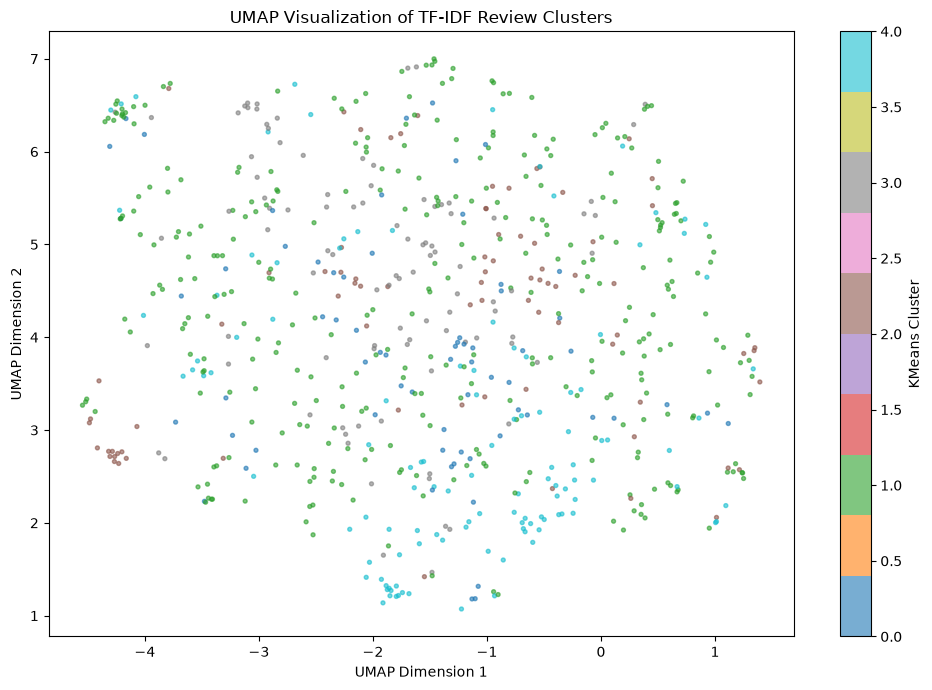

In [18]:
# Visualize training reviews in 2D

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    Z_train_umap[:, 0],
    Z_train_umap[:, 1],
    c=train_clusters,
    cmap="tab10",
    s=8,
    alpha=0.6
)

plt.colorbar(scatter, label="KMeans Cluster")
plt.title("UMAP Visualization of TF-IDF Review Clusters")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.tight_layout()
plt.show()

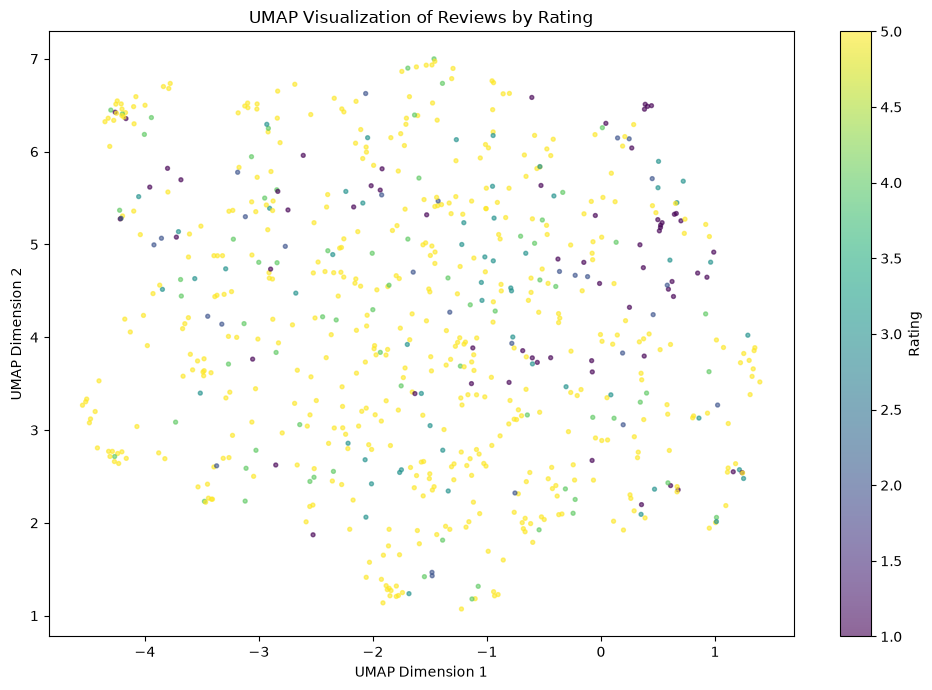

In [19]:
# Visualize training reviews based on rating

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    Z_train_umap[:, 0],
    Z_train_umap[:, 1],
    c=train_df["rating"],
    cmap="viridis",
    s=8,
    alpha=0.6
)

plt.colorbar(scatter, label="Rating")
plt.title("UMAP Visualization of Reviews by Rating")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.tight_layout()
plt.show()

In [23]:
# --------------------------------
# Cluster vs Product Category
# --------------------------------

category_cluster = pd.crosstab(
    train_clustered["text_cluster"],
    train_clustered["main_category"],
    normalize="index"
)

display(category_cluster.round(3))

main_category,AMAZON FASHION,All Beauty,Amazon Home,Appliances,Books,Cell Phones & Accessories,Grocery,Health & Personal Care,Industrial & Scientific,Office Products,Pet Supplies,Premium Beauty,Tools & Home Improvement,Toys & Games,Unknown
text_cluster,,,,,,,,,,,,,,,
0,0.029,0.765,0.029,0.015,0.000,0.000,0.000,0.074,0.000,0.000,0.00,0.029,0.000,0.015,0.044
1,0.018,0.802,0.015,0.000,0.000,0.003,0.003,0.065,0.009,0.000,0.00,0.062,0.009,0.003,0.012
2,0.025,0.662,0.038,0.000,0.000,0.000,0.000,0.100,0.000,0.000,0.00,0.100,0.012,0.012,0.050
3,0.000,0.771,0.010,0.031,0.000,0.000,0.000,0.062,0.010,0.000,0.01,0.073,0.010,0.000,0.021
4,0.009,0.769,0.034,0.000,0.009,0.000,0.000,0.068,0.009,0.009,0.00,0.068,0.009,0.000,0.017


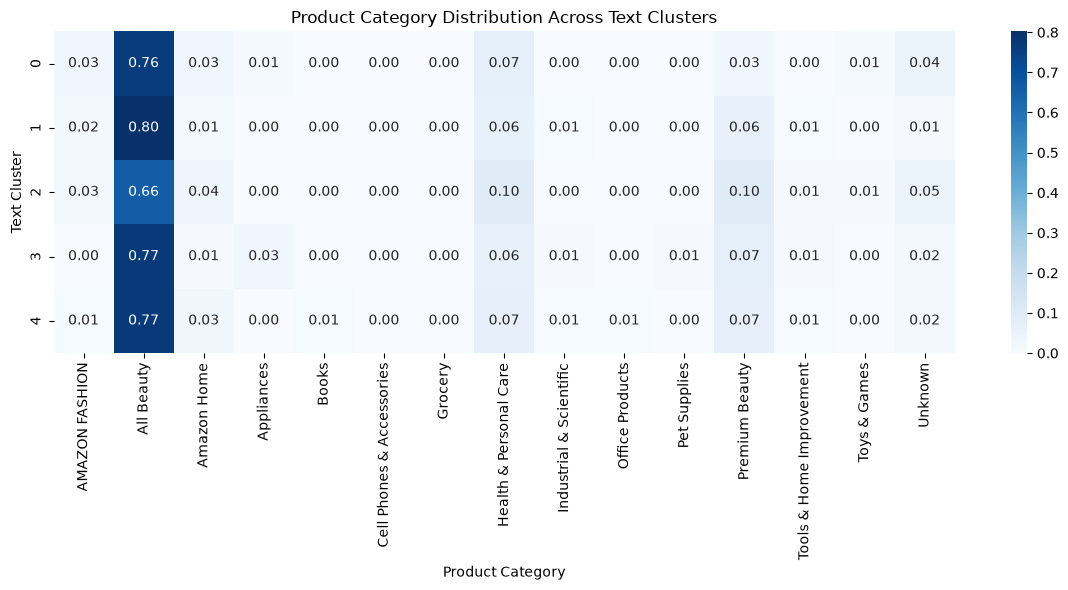

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.heatmap(
    category_cluster,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.title("Product Category Distribution Across Text Clusters")
plt.xlabel("Product Category")
plt.ylabel("Text Cluster")
plt.tight_layout()
plt.show()

In [25]:
# --------------------------------
# Cluster vs Rating distribution
# --------------------------------

rating_cluster = pd.crosstab(
    train_clustered["text_cluster"],
    train_clustered["rating"],
    normalize="index"
)

display(rating_cluster.round(3))

rating,1.0,2.0,3.0,4.0,5.0
text_cluster,,,,,
0,0.059,0.044,0.029,0.235,0.632
1,0.150,0.050,0.094,0.074,0.631
2,0.000,0.050,0.075,0.125,0.750
3,0.083,0.052,0.104,0.104,0.656
4,0.017,0.000,0.060,0.077,0.846


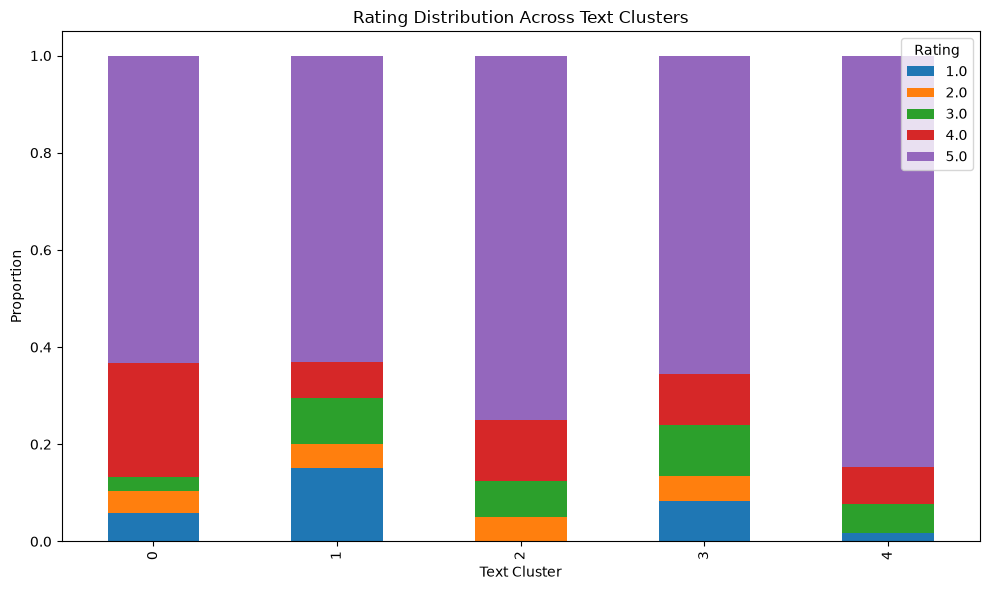

In [26]:
rating_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Rating Distribution Across Text Clusters")
plt.xlabel("Text Cluster")
plt.ylabel("Proportion")
plt.legend(title="Rating")
plt.tight_layout()
plt.show()

In [27]:
# --------------------------------
# Cluster vs User interaction
# --------------------------------

interaction_summary = train_clustered.groupby("text_cluster").agg(
    review_count=("helpful_vote", "count"),
    mean_helpful=("helpful_vote", "mean"),
    median_helpful=("helpful_vote", "median"),
    verified_purchase_rate=("verified_purchase", "mean")
)

display(interaction_summary.round(3))

,review_count,mean_helpful,median_helpful,verified_purchase_rate
text_cluster,,,,
0,68,0.632,0.0,0.956
1,339,2.142,0.0,0.888
2,80,0.200,0.0,0.975
3,96,12.417,0.0,0.885
4,117,3.957,0.0,0.923


In [17]:
OUTPUT_DIR = Path("outputs/phase2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(full_preprocessing_pipeline, OUTPUT_DIR / "multimodal_preprocessing_pipeline.joblib")
modality_audit.to_csv(OUTPUT_DIR / "modality_audit.csv", index=False, encoding="utf-8-sig")
cluster_scores_df.to_csv(OUTPUT_DIR / "kmeans_silhouette_scores.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())


Saved outputs to: C:\Users\SARIR\da_phase2\outputs\phase2
